# 08 — Дальнейшее обучение ради снижения стоимости

Настоящее продолжение обучения весов safety DQN. Мощность, число шардов и формула итоговой стоимости неизменны. Выбор только по validation; test уже известен, поэтому оценка диагностическая. Все изменения локальные.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from agents import MLP
# Полный повтор обучения: python cost_finetuning.py
# Ниже сохранённые результаты; новые эпохи автоматически не запускаются.
display(pd.Series(json.loads(Path('results/cost_finetuning/protocol.json').read_text())))
display(pd.read_csv('results/cost_finetuning/screen.csv'))
display(pd.read_csv('results/cost_finetuning/finalists.csv'))
display(pd.Series(json.loads(Path('results/cost_finetuning/selection.json').read_text())))

configs             [{'cost_weight': 1.0, 'gamma': 0.9, 'stress': ...
screen_episodes                                                   200
final_episodes                                                    600
screen_seed                                                         7
final_seeds                                              [7, 42, 123]
finalists                                                           3
checkpoint                                                         40
initial                                results/safety/m30_e10_s42.npz
initial_sha256      2b6e6b32dce3a3d2becffd9b1cb5486d0ecd29bc05372f...
selection           validation lexicographic overload count, exces...
synthetic_stress    TRAIN-ONLY demand multipliers 0.75,1,1.25,1.5,...
test                Known test, repeated diagnostic evaluation. No...
publication                             Local only; no commit or push
dtype: object

,trial,cost_weight,gamma,stress,lr,cost,server_cost,overload_cost,migration_cost,overloaded_slots,excess_requests,moved_mb,mean_shards,changes
0,0,1.0,0.90,False,0.0001,1203.797933,732.0,462.935848,8.862085,67,125201,45.831304,7.625000,14
1,1,1.0,0.90,True,0.0001,1203.797933,732.0,462.935848,8.862085,67,125201,45.831304,7.625000,14
2,2,1.0,0.99,False,0.0001,1203.797933,732.0,462.935848,8.862085,67,125201,45.831304,7.625000,14
3,3,1.0,0.99,True,0.0001,1203.797933,732.0,462.935848,8.862085,67,125201,45.831304,7.625000,14
4,4,2.0,0.90,False,0.0001,1203.797933,732.0,462.935848,8.862085,67,125201,45.831304,7.625000,14
5,5,2.0,0.90,True,0.0001,1203.797933,732.0,462.935848,8.862085,67,125201,45.831304,7.625000,14
6,6,2.0,0.99,False,0.0001,1203.797933,732.0,462.935848,8.862085,67,125201,45.831304,7.625000,14
7,7,2.0,0.99,True,0.0001,1203.797933,732.0,462.935848,8.862085,67,125201,45.831304,7.625000,14
8,8,4.0,0.90,False,0.0001,1203.797933,732.0,462.935848,8.862085,67,125201,45.831304,7.625000,14
9,9,4.0,0.90,True,0.0001,1203.797933,732.0,462.935848,8.862085,67,125201,45.831304,7.625000,14


,name,trial,seed,cost_weight,gamma,stress,lr,cost,server_cost,overload_cost,migration_cost,overloaded_slots,excess_requests,moved_mb,mean_shards,changes
0,trial_11_seed_7,11,7,4.0,0.99,True,0.0001,1201.967420,734.0,462.935848,5.031572,67,125201,26.021360,7.645833,6
1,trial_11_seed_42,11,42,4.0,0.99,True,0.0001,1201.967420,734.0,462.935848,5.031572,67,125201,26.021360,7.645833,6
2,trial_11_seed_123,11,123,4.0,0.99,True,0.0001,1201.967420,734.0,462.935848,5.031572,67,125201,26.021360,7.645833,6
3,trial_0_seed_7,0,7,1.0,0.90,False,0.0001,1203.797933,732.0,462.935848,8.862085,67,125201,45.831304,7.625000,14
4,trial_0_seed_42,0,42,1.0,0.90,False,0.0001,1203.797933,732.0,462.935848,8.862085,67,125201,45.831304,7.625000,14
5,trial_0_seed_123,0,123,1.0,0.90,False,0.0001,1203.797933,732.0,462.935848,8.862085,67,125201,45.831304,7.625000,14
6,trial_1_seed_7,1,7,1.0,0.90,True,0.0001,1203.797933,732.0,462.935848,8.862085,67,125201,45.831304,7.625000,14
7,trial_1_seed_42,1,42,1.0,0.90,True,0.0001,1203.797933,732.0,462.935848,8.862085,67,125201,45.831304,7.625000,14
8,trial_1_seed_123,1,123,1.0,0.90,True,0.0001,1203.797933,732.0,462.935848,8.862085,67,125201,45.831304,7.625000,14


name                trial_11_seed_7
trial                            11
seed                              7
cost_weight                     4.0
gamma                          0.99
stress                         True
lr                           0.0001
cost                     1201.96742
server_cost                   734.0
overload_cost            462.935848
migration_cost             5.031572
overloaded_slots                 67
excess_requests              125201
moved_mb                   26.02136
mean_shards                7.645833
changes                           6
study_seconds            365.656888
dtype: object

Часть обучения использует синтетические стресс-сценарии, построенные только из train. Их нельзя называть дополнительными реальными наблюдениями. Прежний checkpoint включён как исходный кандидат в каждый запуск; при ухудшении validation он сохраняется.

,cost,server_cost,overload_cost,migration_cost,overloaded_slots,excess_requests,moved_mb,mean_shards,changes
previous_safety,889.649,854.0,9.61,26.039,2.0,2599.0,134.664,4.448,31.0
cost_finetuned,952.246,931.0,14.11,7.137,3.0,3816.0,36.908,4.849,8.0


,seed,cost,server_cost,overload_cost,migration_cost,overloaded_slots,excess_requests,moved_mb,mean_shards,changes
0,7,952.246455,931.0,14.109817,7.136638,3,3816,36.907955,4.848958,8
1,42,952.246455,931.0,14.109817,7.136638,3,3816,36.907955,4.848958,8
2,123,952.246455,931.0,14.109817,7.136638,3,3816,36.907955,4.848958,8


,cost,server_cost,overload_cost,migration_cost,overloaded_slots,excess_requests,moved_mb,mean_shards,changes,initial_shards,preparation_minutes,preparation_cost,preparation_overloaded_slots,preparation_excess_requests,total_with_preparation
strategy,,,,,,,,,,,,,,,
previous_safety,887.423,863.0,0.0,24.423,0,0,126.306,4.495,31,8,90,116.716,6,21095,1004.138
cost_finetuned,973.619,965.0,4.5,4.119,1,1217,21.300,5.026,6,8,90,116.716,6,21095,1090.334


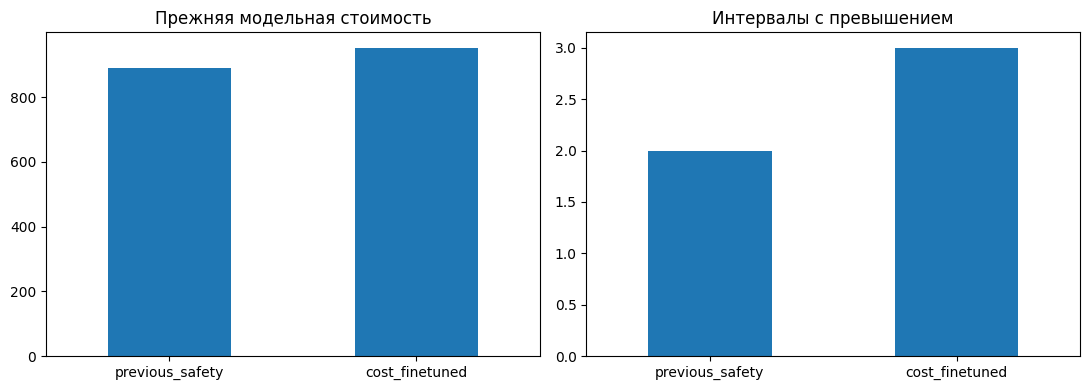

In [2]:
comparison=pd.read_csv('results/cost_finetuning/comparison.csv',index_col=0)
display(comparison.round(3))
display(pd.read_csv('results/cost_finetuning/test_seeds.csv'))
display(pd.read_csv('results/cost_finetuning/reserve_comparison.csv',index_col=0).round(3))
fig,axes=plt.subplots(1,2,figsize=(11,4))
comparison.cost.plot.bar(ax=axes[0],rot=0,title='Прежняя модельная стоимость')
comparison.overloaded_slots.plot.bar(ax=axes[1],rot=0,title='Интервалы с превышением')
fig.tight_layout();fig.savefig('results/cost_finetuning/comparison.png',dpi=150);plt.show()

Экономия не должна оцениваться без перегрузки и полного учёта подготовки. Не заменяйте выбранный seed после просмотра test. Результаты прошлых моделей сохраняются.